# 05 · Pronóstico de ventas — SportSmart Perú

¿Cómo evolucionan las ventas y cuál es su tendencia futura? Se compara una referencia simple con SARIMA, SARIMAX y Prophet.

**Criterio de éxito:** MAPE semanal < 15 % en los últimos 6 meses. Se reportan también el MAPE diario y el error acumulado a 7, 30, 60 y 90 días.

In [1]:
import sys, warnings, logging
from pathlib import Path
ROOT = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(ROOT))
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.models import series
from src.data.estilo_graficos import AZUL, GRIS, NARANJA, SUPERFICIE, TENUE, TINTA, TINTA_2, aplicar_estilo, barras_h, guardar, numero
aplicar_estilo()
res = series.main()
print(res['serie'])

Importing plotly failed. Interactive plots will not work.


{'dias': 1369, 'inicio': '2023-01-01', 'fin': '2026-09-30', 'ventas_total': 13988027.87, 'dias_prueba': 180, 'inicio_prueba': '2026-04-04'}


## 1. Descomposición

La serie se transforma con logaritmo. STL separa tendencia y patrón semanal, y la prueba ADF evalúa la estacionariedad.

In [2]:
d = res['descomposicion']; print({k: v for k, v in d.items() if k != 'indice_dia_semana'})
pd.Series(d['indice_dia_semana'], name='índice').to_frame().T

{'adf_p_original': 0.0295, 'adf_p_log_dif7': 1.23e-16, 'fuerza_estacional_semanal': 0.272, 'fuerza_tendencia': 0.559, 'efecto_quincena': 1.264}


,Lun,Mar,Mié,Jue,Vie,Sáb,Dom
índice,0.958,0.94,0.958,0.965,0.968,1.107,1.104


## 2. Comparación en los últimos 6 meses

Los modelos se entrenan hasta el 3 de abril de 2026 y pronostican 180 días sin ver los datos reales. Los órdenes de SARIMA y SARIMAX se eligen por AIC solo con entrenamiento.

Órdenes: [2, 0, 2] [1, 0, 2] | Mejor: Prophet | Cumple la meta: True


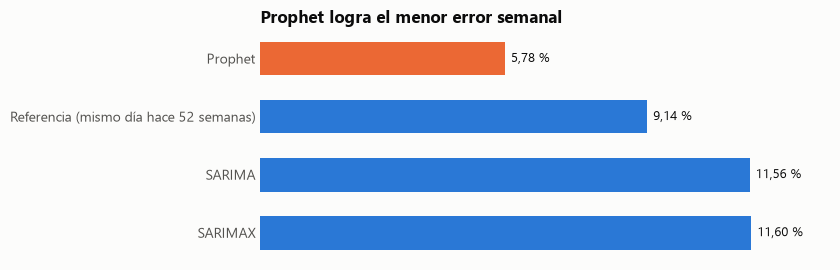

,mape_diario,mape_semanal,rmse_diario,mae_diario,r2_diario,error_total_pct
Prophet,16.61,5.78,2167.0,1763.0,0.302,0.70
Referencia (mismo día hace 52 semanas),23.26,9.14,3120.0,2537.0,-0.446,-8.07
SARIMA,18.92,11.56,2629.0,2057.0,-0.026,-2.79
SARIMAX,17.03,11.60,2491.0,1935.0,0.078,-7.29


In [3]:
hold = pd.DataFrame(res['prueba_6_meses']).T.sort_values('mape_semanal')
print('Órdenes:', res['ordenes']['SARIMA'], res['ordenes']['SARIMAX'], '| Mejor:', res['mejor_modelo'], '| Cumple la meta:', res['cumple_meta'])
fig, ax = plt.subplots(figsize=(8.5, 2.8))
barras_h(ax, list(hold.index), list(hold.mape_semanal), [NARANJA] + [AZUL] * 3, lambda v: numero(v, 2) + ' %')
ax.set_title(f"{hold.index[0]} logra el menor error semanal")
guardar(fig, 'comparacion_series')
hold

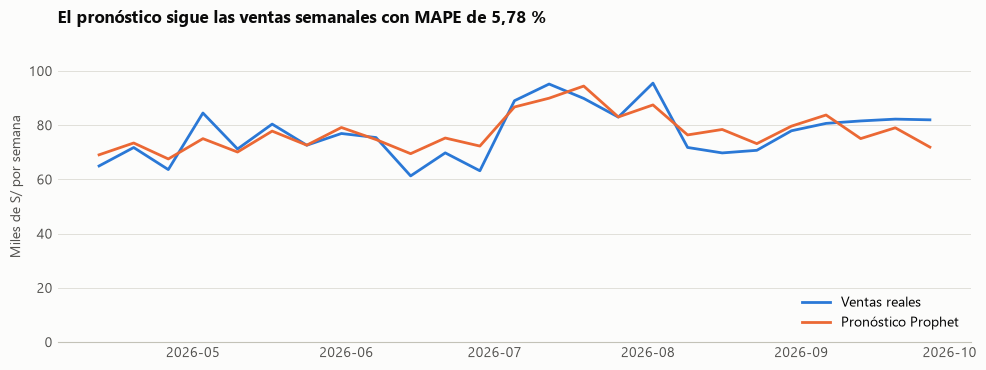

In [4]:
cp = res['curva_prueba']; idx = pd.to_datetime(cp['fechas'])
sem = lambda v: series._semanal(idx, np.array(v, dtype=float)) / 1000
real, pro = sem(cp['real']), sem(cp['Prophet'])
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(real.index, real.values, color=AZUL, lw=2, label='Ventas reales'); ax.plot(pro.index, pro.values, color=NARANJA, lw=2, label='Pronóstico Prophet')
ax.set_ylim(0, real.max() * 1.2); ax.set_ylabel('Miles de S/ por semana'); ax.legend(loc='lower right')
ax.set_title(f"El pronóstico sigue las ventas semanales con MAPE de {numero(res['prueba_6_meses']['Prophet']['mape_semanal'], 2)} %")
guardar(fig, 'pronostico_prueba')

## 3. Validación por horizonte

Se reentrena en 4 puntos de partida y se promedia el error acumulado absoluto (%).

In [5]:
pd.DataFrame(res['validacion_por_horizonte']['error_acumulado_medio_pct']).T.rename(columns=lambda h: f'{h} días')

,7 días,30 días,60 días,90 días
Referencia (mismo día hace 52 semanas),13.92,7.18,6.55,7.08
SARIMA,15.11,10.52,6.96,8.51
SARIMAX,10.83,8.13,5.50,6.16
Prophet,5.76,2.99,1.50,2.20


## 4. Validación en temporada alta

Los últimos 6 meses no incluyen noviembre ni diciembre, así que se prueba también octubre a diciembre de 2025, entrenando hasta setiembre.

In [6]:
pd.DataFrame(res['temporada_alta_2025']['metricas']).T

,mape_diario,mape_semanal,rmse_diario,mae_diario,r2_diario,error_total_pct
Referencia (mismo día hace 52 semanas),18.56,8.81,3165.0,2489.0,0.268,-7.16
SARIMA,29.42,30.27,5589.0,4513.0,-1.282,-31.69
SARIMAX,14.69,5.63,2657.0,2066.0,0.484,-5.00
Prophet,15.24,5.68,2420.0,1982.0,0.572,3.20


## 5. Pronóstico de los próximos 90 días

Modelo entrenado con toda la historia. **Supuesto:** el calendario de campañas repite el de hace 52 semanas.

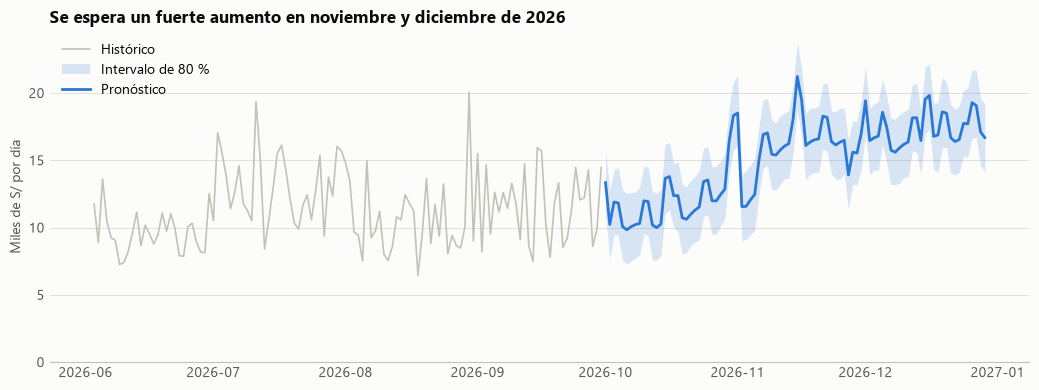

,pronostico,limite_inferior_80,limite_superior_80,mismo_periodo_anio_anterior,variacion_pct
7 días,77268.0,70968.0,83788.0,68467.0,12.9
30 días,352141.0,338719.0,365050.0,313004.0,12.5
60 días,835736.0,816008.0,854267.0,749759.0,11.5
90 días,1358062.0,1333843.0,1382036.0,1226636.0,10.7


In [7]:
f = pd.read_csv(ROOT / 'reports' / 'pronostico_ventas.csv', parse_dates=['fecha'])
hist = series.cargar().ventas.iloc[-120:]
fig, ax = plt.subplots(figsize=(10.5, 4))
ax.plot(hist.index, hist.values / 1000, color=GRIS, lw=1.2, label='Histórico')
ax.fill_between(f.fecha, f.limite_inferior / 1000, f.limite_superior / 1000, color=AZUL, alpha=.18, linewidth=0, label='Intervalo de 80 %')
ax.plot(f.fecha, f.pronostico / 1000, color=AZUL, lw=2, label='Pronóstico')
ax.set_ylim(0); ax.set_ylabel('Miles de S/ por día'); ax.legend(loc='upper left')
ax.set_title('Se espera un fuerte aumento en noviembre y diciembre de 2026')
guardar(fig, 'pronostico_90d')
t = pd.DataFrame(res['pronostico_futuro']).T; t.index = [f'{h} días' for h in t.index]; t['variacion_pct'] = (100 * (t.pronostico / t.mismo_periodo_anio_anterior - 1)).round(1); t

## 6. Conclusiones

- **Meta cumplida:** Prophet logra MAPE semanal de 5,78 %, frente a la meta de 15 %. Supera a la referencia (9,14 %), SARIMA (11,56 %) y SARIMAX (11,60 %).
- **El MAPE diario (16,61 %) no alcanza 15 %.** Las ventas de cada día son muy variables, por lo que el modelo sirve para planificar por semana o periodo, no para cada día.
- **Por horizonte**, Prophet promedia un error acumulado de 5,76 % a 7 días y de 3,00 % o menos a 30, 60 y 90 días.
- **Temporada alta:** en octubre-diciembre de 2025, Prophet logra MAPE semanal de 5,68 % y SARIMAX 5,63 %, prácticamente iguales. SARIMA sin variables externas falla (30,27 %) porque no conoce las campañas ni la estacionalidad anual.
- **Patrones:** sábados y domingos venden 10-11 % sobre el promedio y los días de quincena 26 % más que los demás.

**Pronóstico base (desde octubre de 2026):** S/ 77 268 a 7 días, S/ 352 141 a 30, S/ 835 736 a 60 y S/ 1 358 062 a 90, alrededor de 13 % sobre el mismo periodo del año anterior a 7 días y 11 % a 90.

**Limitaciones:** el pronóstico depende de que se repita el calendario de campañas; el modelo no incluye LSTM porque los datos ya se explican bien con modelos más simples; y los intervalos de los totales pueden ser estrechos porque el modelo trata cada día como independiente.